# EDA rápido — data dummy Caso Factoring
Validación de la muestra generada por `generate_data.py`: estructura, distribuciones, integridad entre tablas y señal plantada.
Ventana 202501–202606 · corte 202512 · target 202601–202606.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
sns.set_theme(style="whitegrid", palette="deep"); pd.set_option("display.float_format", "{:,.2f}".format)

D = "data/sample"
t1 = pd.read_csv(f"{D}/1_maestro_empresas.csv", dtype={"ciiu": str}, parse_dates=["fecha_inicio_actividades", "fecha_alta_cliente"])
t2 = pd.read_csv(f"{D}/2_transacciones.csv")
t3 = pd.read_csv(f"{D}/3_operaciones_factoring.csv", parse_dates=["fecha_operacion", "fecha_vencimiento"])
t4 = pd.read_csv(f"{D}/4_perfil_historico.csv")
gt = pd.read_csv(f"{D}/_ground_truth.csv")
TC, CORTE = 3.75, 202512
t2["monto_pen"] = t2.monto * np.where(t2.moneda == "USD", TC, 1)
t3["periodo"] = t3.fecha_operacion.dt.strftime("%Y%m").astype(int)
for n, d in [("1 Maestro", t1), ("2 Transacciones", t2), ("3 Factoring", t3), ("4 Perfil", t4)]:
    print(f"{n:16s} {d.shape[0]:>8,} filas x {d.shape[1]} cols")

1 Maestro           4,000 filas x 16 cols
2 Transacciones   138,620 filas x 10 cols
3 Factoring         2,903 filas x 15 cols
4 Perfil           68,249 filas x 11 cols


## 1. Estructura y nulos

In [2]:
for n, d in [("1 Maestro", t1), ("2 Transacciones", t2), ("3 Factoring", t3), ("4 Perfil", t4)]:
    nul = d.isna().mean().loc[lambda s: s > 0]
    print(f"--- {n}: nulos -> {nul.round(3).to_dict() if len(nul) else 'ninguno'}")
t1.head()

--- 1 Maestro: nulos -> {'departamento': 0.051, 'provincia': 0.051, 'distrito': 0.08, 'score_riesgo': 0.068, 'rating': 0.068}
--- 2 Transacciones: nulos -> ninguno
--- 3 Factoring: nulos -> ninguno
--- 4 Perfil: nulos -> {'ventas_mes': 0.019}


,id_empresa,rubro,ciiu,sector,segmento,ventas_anuales,num_empleados,departamento,provincia,distrito,fecha_inicio_actividades,antiguedad_anios,fecha_alta_cliente,score_riesgo,rating,flag_lead
0,E0004044,Servicios,8299,Terciario,Pequeña,"2,988,833.41",41,Arequipa,Camaná,Camaná,2009-05-11,16.60,2014-04-11,737.00,B,0
1,E0002744,Servicios,6201,Terciario,Pequeña,"8,148,212.79",85,Lima,Lima,San Juan de Lurigancho,2022-11-21,3.10,2024-06-20,NaN,NaN,0
2,E0000158,Servicios,7110,Terciario,Mediana,"12,806,327.30",129,Lambayeque,Ferreñafe,Ferreñafe,2023-03-29,2.80,2023-11-08,801.00,A,0
3,E0003991,Comercio,4649,Terciario,Pequeña,"9,885,231.18",54,Arequipa,Arequipa,Arequipa,2017-06-23,8.50,2024-03-21,650.00,B,1
4,E0000015,Construcción,4100,Secundario,Micro,"210,221.26",2,Lima,Cañete,Cañete,2024-05-16,1.60,2024-10-01,528.00,D,0


In [3]:
t2.head()

,id_transaccion,id_pagador,id_receptor,periodo,monto,moneda,n_trx,canal,dias_credito,monto_pen
0,T000000001,E0004746,E0004044,202602,"15,142.59",PEN,3,transferencia,60,"15,142.59"
1,T000000002,E0004746,E0004044,202603,"36,762.02",PEN,1,transferencia,60,"36,762.02"
2,T000000003,E0004746,E0004044,202604,"28,324.80",PEN,4,transferencia,60,"28,324.80"
3,T000000004,E0004746,E0004044,202605,"24,736.51",PEN,2,transferencia,60,"24,736.51"
4,T000000005,E0004746,E0004044,202606,"30,396.85",PEN,4,transferencia,60,"30,396.85"


In [4]:
t3.head()

,id_operacion,id_cedente,id_aceptante,fecha_operacion,fecha_vencimiento,plazo_dias,monto_factura,monto_desembolsado,tasa_anual,comision,moneda,tipo,estado,dias_atraso,periodo
0,F0000001,E0000061,E0004991,2025-01-01,2025-04-22,111,"4,205.08","3,399.81",0.13,50.00,PEN,factoring,pagada,2,202501
1,F0000002,E0001037,E0001868,2025-01-01,2025-02-05,35,"10,500.81","9,280.08",0.15,50.00,PEN,factoring,pagada,0,202501
2,F0000003,E0001318,E0003077,2025-01-01,2025-04-20,109,"10,733.51","9,675.10",0.17,50.00,PEN,factoring,pagada,0,202501
3,F0000004,E0001450,E0004594,2025-01-01,2025-03-01,59,"10,835.01","9,071.66",0.10,50.00,USD,factoring,pagada,12,202501
4,F0000005,E0001457,E0002797,2025-01-01,2025-02-10,40,"8,085.21","6,839.78",0.12,50.00,PEN,factoring,pagada,0,202501


In [5]:
t4.head()

,id_empresa,periodo,ventas_mes,n_productos,tiene_cuenta,tiene_credito,tiene_tarjeta,saldo_promedio,saldo_deuda,uso_linea_credito,usa_factoring
0,E0004044,202501,"226,411.79",3,1,0,0,"49,101.55",0.00,0.00,0
1,E0004044,202502,"194,089.49",3,1,0,0,"43,017.52",0.00,0.00,0
2,E0004044,202503,"230,623.76",3,1,0,0,"99,180.23",0.00,0.00,0
3,E0004044,202504,"267,190.28",3,1,0,0,"95,759.97",0.00,0.00,0
4,E0004044,202505,"290,045.79",3,1,0,0,"75,880.02",0.00,0.00,0


## 2. Maestro de empresas

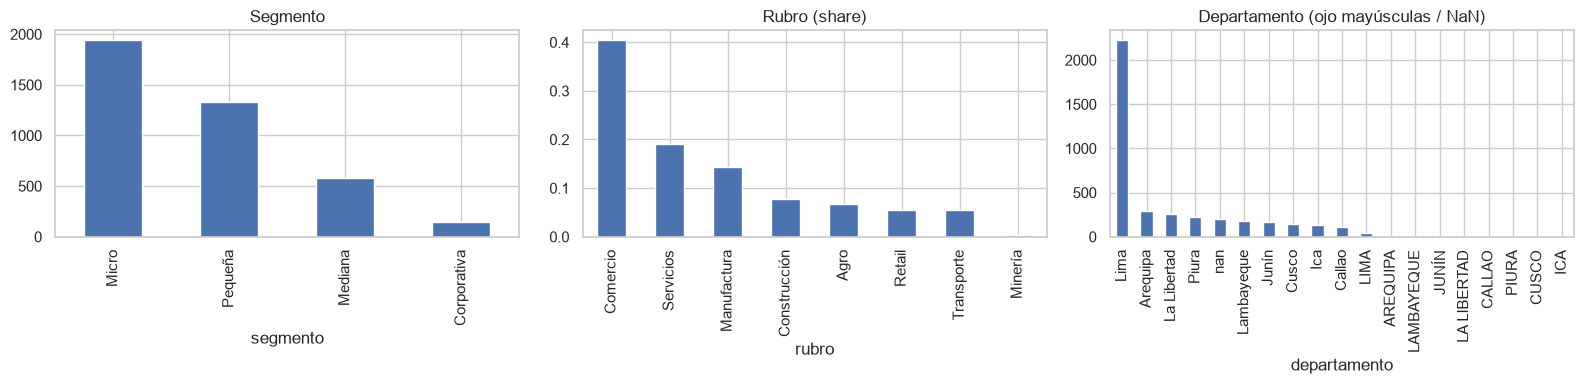

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
t1.segmento.value_counts().plot.bar(ax=ax[0], title="Segmento")
t1.rubro.value_counts(normalize=True).plot.bar(ax=ax[1], title="Rubro (share)")
t1.departamento.value_counts(dropna=False).plot.bar(ax=ax[2], title="Departamento (ojo mayúsculas / NaN)")
plt.tight_layout()

flag_lead entre Pyme: 0.1


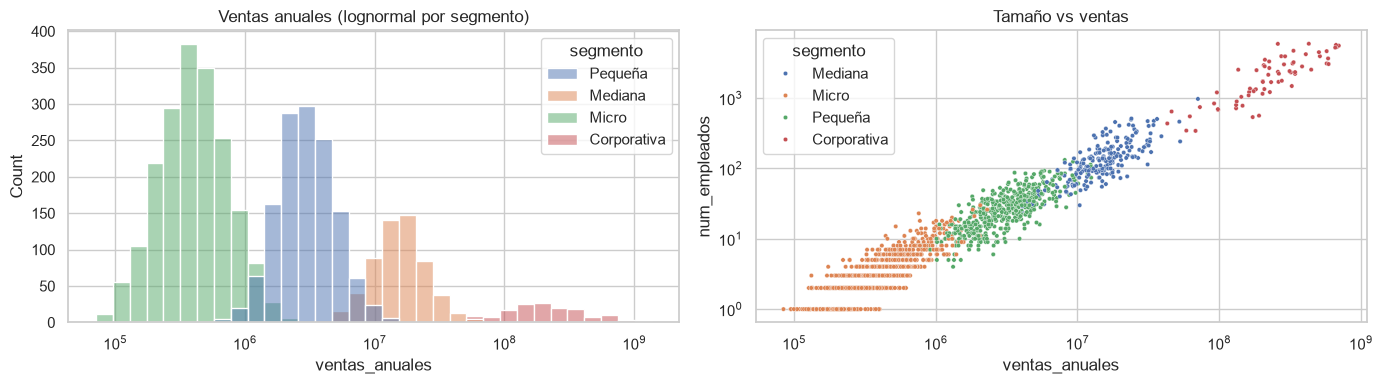

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=t1, x="ventas_anuales", hue="segmento", log_scale=True, ax=ax[0]).set_title("Ventas anuales (lognormal por segmento)")
sns.scatterplot(data=t1.sample(1500, random_state=0), x="ventas_anuales", y="num_empleados", hue="segmento", s=10, ax=ax[1])
ax[1].set(xscale="log", yscale="log", title="Tamaño vs ventas")
plt.tight_layout()
print("flag_lead entre Pyme:", t1.loc[t1.segmento != "Corporativa", "flag_lead"].mean().round(3))

## 3. Transacciones (red comercial)

aceptantes observados en T3: 134 | no clientes en T2: 940
% filas T2 con pagador aceptante: 45.2%
% filas T2 con no cliente involucrado: 30.4%


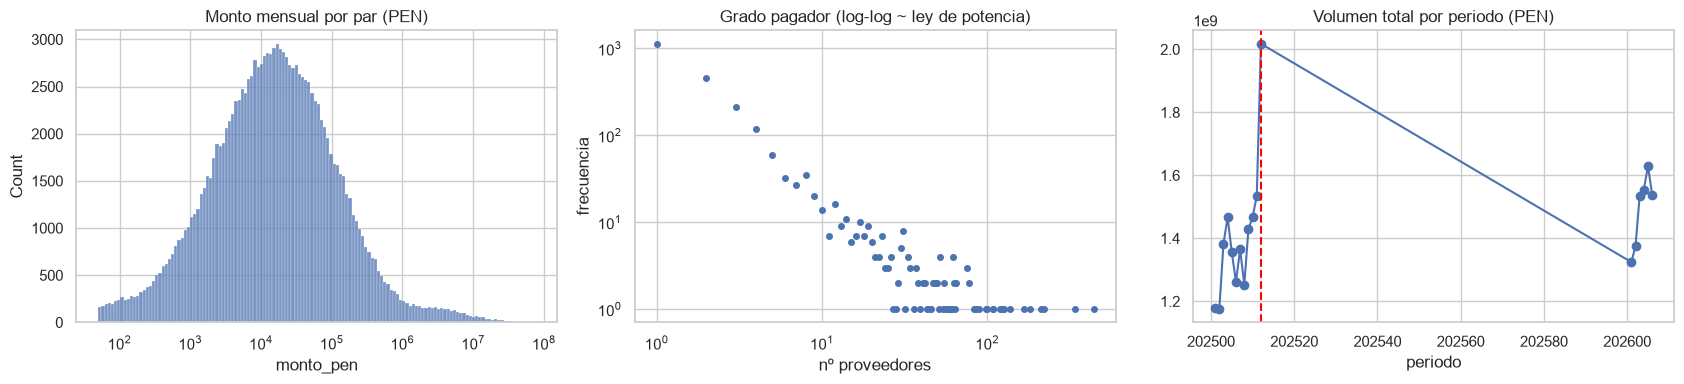

In [8]:
acept = set(t3.id_aceptante)
cli = set(t1.id_empresa)
nocli = (set(t2.id_pagador) | set(t2.id_receptor)) - cli
print(f"aceptantes observados en T3: {len(acept)} | no clientes en T2: {len(nocli):,}")
print(f"% filas T2 con pagador aceptante: {t2.id_pagador.isin(acept).mean():.1%}")
print(f"% filas T2 con no cliente involucrado: {(t2.id_pagador.isin(nocli) | t2.id_receptor.isin(nocli)).mean():.1%}")

pares = t2[["id_pagador", "id_receptor"]].drop_duplicates()
deg_in = pares.id_pagador.value_counts()   # nº de proveedores de cada pagador
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(t2.monto_pen, log_scale=True, ax=ax[0]).set_title("Monto mensual por par (PEN)")
vc = deg_in.value_counts().sort_index()
ax[1].loglog(vc.index, vc.values, "o", ms=4); ax[1].set(title="Grado pagador (log-log ~ ley de potencia)", xlabel="nº proveedores", ylabel="frecuencia")
t2.groupby("periodo").monto_pen.sum().plot(ax=ax[2], marker="o", title="Volumen total por periodo (PEN)")
ax[2].axvline(CORTE, color="red", ls="--")
plt.tight_layout()

## 4. Operaciones de factoring

,proportion,proportion,proportion
pagada,0.96,NaN,NaN
vigente,0.04,NaN,NaN
vencida,0.00,NaN,NaN
factoring,NaN,0.85,NaN
confirming,NaN,0.10,NaN
descuento,NaN,0.05,NaN
PEN,NaN,NaN,0.92
USD,NaN,NaN,0.08


cedentes únicos: 449 | ops por cedente (mediana): 6.0


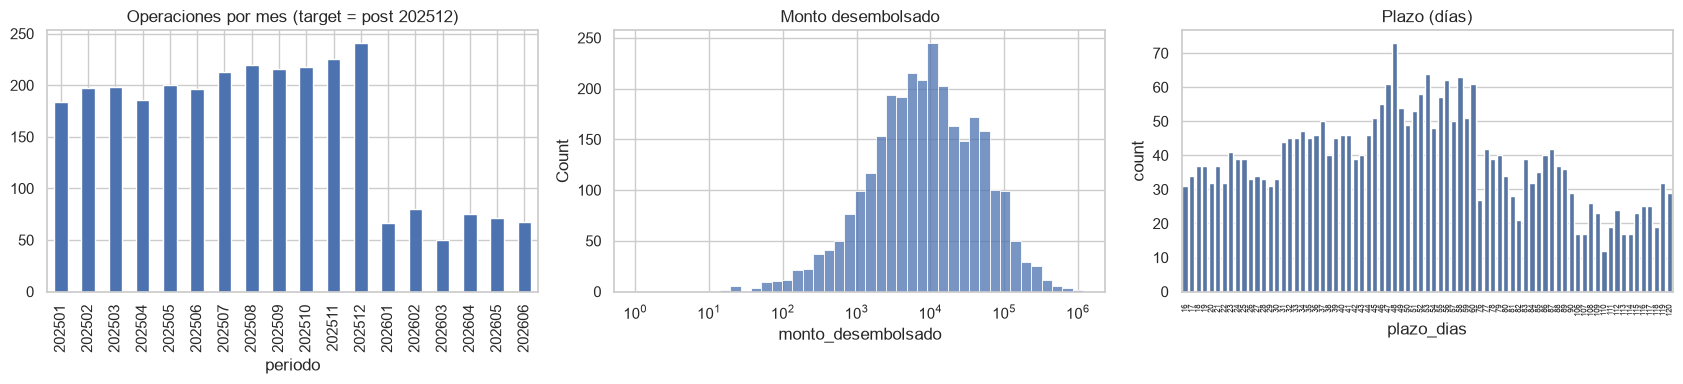

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
t3.groupby("periodo").size().plot.bar(ax=ax[0], title="Operaciones por mes (target = post 202512)")
sns.histplot(t3.monto_desembolsado, log_scale=True, ax=ax[1]).set_title("Monto desembolsado")
sns.countplot(data=t3, x="plazo_dias", ax=ax[2]); ax[2].set_title("Plazo (días)"); ax[2].tick_params(axis="x", labelsize=6, rotation=90)
plt.tight_layout()
display(pd.concat([t3.estado.value_counts(normalize=True), t3.tipo.value_counts(normalize=True), t3.moneda.value_counts(normalize=True)], axis=1))
print(f"cedentes únicos: {t3.id_cedente.nunique()} | ops por cedente (mediana): {t3.groupby('id_cedente').size().median()}")

## 5. Perfil histórico

{'tiene_cuenta': 0.965, 'tiene_credito': 0.415, 'tiene_tarjeta': 0.341, 'usa_factoring': 0.036}
filas por empresa: {'min': 3.0, '50%': 18.0, 'max': 18.0}


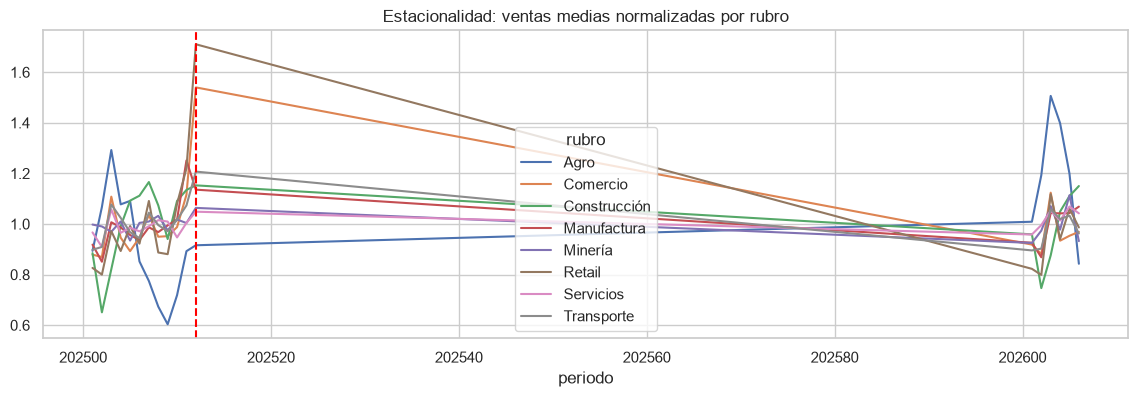

In [10]:
p = t4.merge(t1[["id_empresa", "rubro"]], on="id_empresa")
saz = p.groupby(["rubro", "periodo"]).ventas_mes.mean().unstack(0)
(saz / saz.mean()).plot(figsize=(14, 4), title="Estacionalidad: ventas medias normalizadas por rubro")
plt.axvline(CORTE, color="red", ls="--")
print(t4[["tiene_cuenta", "tiene_credito", "tiene_tarjeta", "usa_factoring"]].mean().round(3).to_dict())
print("filas por empresa:", t4.groupby("id_empresa").size().describe()[["min", "50%", "max"]].to_dict())

## 6. Chequeos de integridad

In [11]:
chk = {}
chk["T3/T4 ids existen en T1"] = t3.id_cedente.isin(cli).all() and t3.id_aceptante.isin(cli).all() and t4.id_empresa.isin(cli).all()
chk["T4 solo clientes"] = not t4.id_empresa.isin(nocli).any()

# factoring con relación previa (aceptante -> cedente) en T2, en o antes del mes de la operación
rel = t2.groupby(["id_pagador", "id_receptor"]).periodo.min().rename("primer_periodo")
x = t3.merge(rel, left_on=["id_aceptante", "id_cedente"], right_index=True, how="left")
chk["todo factoring tiene relación en T2"] = x.primer_periodo.notna().all()
chk["relación es previa/simultánea"] = (x.primer_periodo <= x.periodo).all()

# monto factura <= volumen transado ese mes con ese aceptante
vol = t2.groupby(["id_pagador", "id_receptor", "periodo"], as_index=False).monto.sum()
y = t3.groupby(["id_aceptante", "id_cedente", "periodo"], as_index=False).monto_factura.sum().merge(
    vol, left_on=["id_aceptante", "id_cedente", "periodo"], right_on=["id_pagador", "id_receptor", "periodo"], how="left")
chk["monto_factura <= volumen transado"] = (y.monto_factura <= y.monto + 0.01).all()
chk["desembolsado <= factura"] = (t3.monto_desembolsado <= t3.monto_factura).all()
chk["operación < vencimiento"] = (t3.fecha_operacion < t3.fecha_vencimiento).all()

alta = t1.set_index("id_empresa").fecha_alta_cliente
chk["factoring después del alta"] = (t3.fecha_operacion > t3.id_cedente.map(alta)).all()
alta_p = t4.id_empresa.map(alta).dt.strftime("%Y%m").astype(int)
chk["T4 no antes del alta"] = (t4.periodo >= alta_p.clip(lower=202501)).all()
chk["alta >= inicio actividades"] = (t1.fecha_alta_cliente >= t1.fecha_inicio_actividades).all()
cob = t2[t2.id_receptor.isin(cli)].groupby(["id_receptor", "periodo"]).monto_pen.sum()
v = t4.set_index(["id_empresa", "periodo"]).ventas_mes
z = cob.to_frame("cob").join(v.rename_axis(["id_receptor", "periodo"]), how="inner").dropna()
chk["cobros de red <= ventas_mes"] = (z.cob <= z.ventas_mes * 1.001).all()
uf = t4[t4.usa_factoring == 1].set_index(["id_empresa", "periodo"]).index
chk["usa_factoring (T4) == ops en T3"] = set(uf) == set(zip(t3.id_cedente, t3.periodo))
chk["sin pares nocli-nocli"] = not (t2.id_pagador.isin(nocli) & t2.id_receptor.isin(nocli)).any()
pd.Series(chk, name="OK").to_frame()

,OK
T3/T4 ids existen en T1,True
T4 solo clientes,True
todo factoring tiene relación en T2,True
relación es previa/simultánea,True
monto_factura <= volumen transado,True
desembolsado <= factura,True
operación < vencimiento,True
factoring después del alta,True
T4 no antes del alta,True
alta >= inicio actividades,True


## 7. Señal plantada
Reconstruyo las features **solo con data ≤ corte** (como lo haría un equipo) y verifico que predicen el target post-corte.

Tasa de conversión post-corte:


,mean,sum,count
flag_lead,,,
0,0.02,65,3356
1,0.11,41,385


,conv | factoring previo
fact_previo,
0,0.02
1,0.12


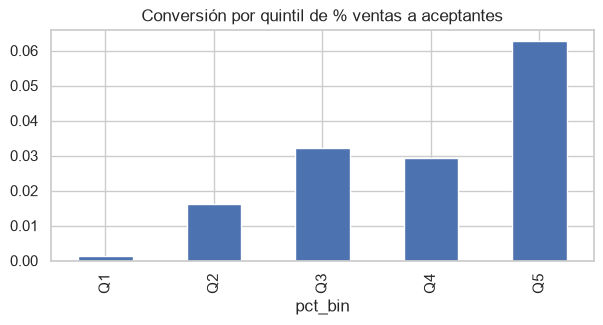

In [12]:
pre4 = t4[t4.periodo <= CORTE]
ventas_pre = pre4.groupby("id_empresa").ventas_mes.sum()
cob_acept = t2[(t2.periodo <= CORTE) & t2.id_pagador.isin(acept)].groupby("id_receptor").monto_pen.sum()
v_ini = pre4[pre4.periodo.between(202501, 202503)].groupby("id_empresa").ventas_mes.sum()
v_fin = pre4[pre4.periodo.between(202510, 202512)].groupby("id_empresa").ventas_mes.sum()

f = t1[(t1.segmento != "Corporativa") & (t1.fecha_alta_cliente <= "2025-12-31")].set_index("id_empresa")[["flag_lead", "segmento"]]
f["pct_acept"] = (cob_acept.reindex(f.index).fillna(0) / ventas_pre.reindex(f.index)).clip(0, 1).fillna(0)
f["crec"] = np.log((v_fin.reindex(f.index) + 1) / (v_ini.reindex(f.index) + 1)).clip(-1, 1).fillna(0)
f["fact_previo"] = f.index.isin(t3.loc[t3.periodo <= CORTE, "id_cedente"]).astype(int)
f["target"] = f.index.isin(t3.loc[t3.periodo > CORTE, "id_cedente"]).astype(int)

print("Tasa de conversión post-corte:")
display(f.groupby("flag_lead").target.agg(["mean", "sum", "count"]))
display(f.groupby("fact_previo").target.mean().rename("conv | factoring previo").to_frame())
f["pct_bin"] = pd.qcut(f.pct_acept.rank(method="first"), 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
f.groupby("pct_bin", observed=True).target.mean().plot.bar(title="Conversión por quintil de % ventas a aceptantes", figsize=(7, 3));

In [13]:
X = f[["pct_acept", "crec", "fact_previo", "flag_lead"]]
lr = LogisticRegression().fit(X, f.target)
print("coeficientes (plantados: 1.5, 0.8, 1.0, 0.5 | b0 = -4):")
print(dict(zip(X.columns, lr.coef_[0].round(2))), "b0 =", lr.intercept_.round(2))
print(f"AUC in-sample: {roc_auc_score(f.target, lr.predict_proba(X)[:, 1]):.3f}")

g = gt.set_index("id_empresa").reindex(f.index)
print(f"corr pct_acept reconstruido vs latente: {np.corrcoef(f.pct_acept, g.pct_ventas_aceptantes)[0,1]:.3f}")
print(f"target reconstruido == ground truth: {(f.target == g.convierte).mean():.3%}")

coeficientes (plantados: 1.5, 0.8, 1.0, 0.5 | b0 = -4):
{'pct_acept': np.float64(0.9), 'crec': np.float64(0.45), 'fact_previo': np.float64(1.33), 'flag_lead': np.float64(0.86)} b0 = [-4.25]
AUC in-sample: 0.738
corr pct_acept reconstruido vs latente: 0.903
target reconstruido == ground truth: 100.000%


## 8. Casos borde

In [14]:
rec = set(t2.id_receptor) | set(t2.id_pagador)
print(f"clientes sin ninguna transacción en T2: {(~t1.id_empresa.isin(rec)).sum()}")
print(f"conversores sin lead: {((f.target == 1) & (f.flag_lead == 0)).sum()} de {f.target.sum()}")
nc = t2[t2.id_receptor.isin(nocli) & t2.id_pagador.isin(acept)].groupby("id_receptor").monto_pen.sum().sort_values(ascending=False)
print(f"no clientes que venden a aceptantes: {len(nc)} (leads de captación, problema B)")
nc.head(10).to_frame("cobro de aceptantes (PEN)")

clientes sin ninguna transacción en T2: 110
conversores sin lead: 65 de 106
no clientes que venden a aceptantes: 685 (leads de captación, problema B)


,cobro de aceptantes (PEN)
id_receptor,
E0001412,"503,283,045.99"
E0003583,"442,605,315.66"
E0001420,"334,323,442.17"
E0003086,"300,043,346.09"
E0003948,"285,490,563.80"
E0001564,"248,804,459.87"
E0000983,"136,122,298.72"
E0004283,"134,241,486.82"
E0000904,"91,377,251.82"
